# Lensless imaging: pinholes, coded apertures and diffuser cameras

A lens maps every point of the object onto one point of the sensor. Without
a lens, every point of the object lights up a whole pattern on the sensor,
and the picture is the sum of these patterns: a convolution of the scene
with the point spread function (PSF) of whatever sits in front of the
sensor. Whether an image can still be had depends on that PSF. If it is
small, the picture *is* the image (the pinhole camera). If it is large but
known and well conditioned, the image can be computed from the picture.

This notebook goes through three lensless cameras, from the oldest to one
of the newest, with the tools of `pyoptics.lensless`:

1. **The pinhole camera.** The blur is the larger of the geometric shadow of
   the hole and its diffraction spot. Fresnel propagation through holes of
   different sizes (`propagators.fresnel_scaled()`) shows the best diameter
   near Rayleigh's $d \approx 1.9\sqrt{\lambda f}$, and how different
   criteria of "sharpest" place it between $1.5$ and $2\sqrt{\lambda f}$,
   each in agreement with its analytic value.
2. **The coded aperture.** A mask with thousands of holes (a MURA) collects
   thousands of times more light. Its picture is unrecognizable, but a
   correlation with a decoding array recovers the scene exactly. Whether the
   extra light also buys a better signal-to-noise ratio depends on the
   scene: Monte Carlo photon noise against Fenimore's formula. Diffraction
   sets the smallest useful mask element, the same $\sqrt{\lambda z}$ as for
   the pinhole.
3. **The diffuser camera (DiffuserCam).** A smooth random phase plate a few
   millimetres in front of a bare sensor makes a PSF of sharp caustics. The
   PSF shifts with the position of the source and scales with its
   distance; deconvolution (Wiener, or ADMM with total variation on a
   sensor smaller than the picture) recovers a 2D scene, and a rescaled PSF
   refocuses onto another depth.

Camera noise comes from `processing.CameraNoiser` (notebook 18). Speckle and
random phase screens as scatterers are the subject of notebook 73
(wavefront shaping); here the phase screen is smooth and the light
incoherent, so the PSF is a caustic network instead of speckle.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.signal import fftconvolve

from pyoptics import lensless as ll
from pyoptics import sketch
from pyoptics.processing import CameraNoiser, Scaler
from pyoptics.propagators import fresnel_scaled, rayleigh_sommerfeld_I_TF, propagate_padded
from pyoptics.utils import grid2d
from pyoptics.wavefront_shaping import random_phase_screen

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
t_start = time.time()
WL = 0.55                                   # µm, all lengths in µm


def text_image(text, n, fontsize, x=0.5, y=0.5):
    """White text on black, rendered by matplotlib, as an n x n array (row 0 at the bottom)."""
    fig = plt.figure(figsize=(n/100, n/100), dpi=100)
    fig.text(x, y, text, ha="center", va="center", fontsize=fontsize, weight="bold")
    fig.canvas.draw()
    a = 1 - np.asarray(fig.canvas.buffer_rgba())[..., 0]/255.0
    plt.close(fig)
    return np.flipud(a)


def siemens_star(X, Y, x0, y0, radius, spokes=12):
    r, th = np.hypot(X - x0, Y - y0), np.arctan2(Y - y0, X - x0)
    return ((r < radius) & (np.cos(spokes*th) > 0)).astype(float)

## 1. The pinhole camera

### Setup

A screen at the distance $v$ behind a hole of diameter $d$ catches the
light of a distant object. Geometrically every object point makes a disk of
diameter $d$, and the image is sharper the smaller the hole. But a small
hole diffracts: the far-field spot of a hole has the diameter
$2.44\,\lambda v/d$ (the Airy disk), larger the smaller the hole. The two
blurs are equal for $d^2 \approx 2.44\,\lambda v$, and the scale of the
optimum is $\sqrt{\lambda v}$, the radius of the first Fresnel zone. For
an object at the finite distance $u$, $v$ is replaced by
$z = (1/u + 1/v)^{-1}$ (`ll.rayleigh_pinhole_diameter()` takes both).

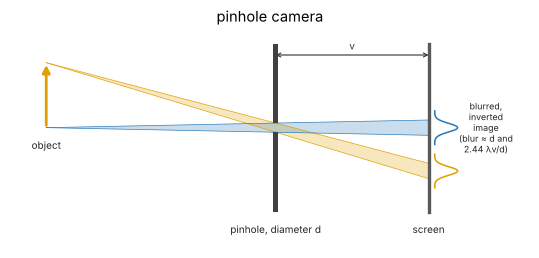

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sketch.lensless_camera(ax, "pinhole", title="pinhole camera")
plt.show()

### PSF against hole size

For a plane wave through a circular hole, the field on the screen is a
Fresnel integral, evaluated with `fresnel_scaled()` on a fine output grid
for hole diameters from $0.6$ to $4\sqrt{\lambda v}$ ($v = 50$ mm,
$\lambda = 0.55$ µm, so $\sqrt{\lambda v} = 166$ µm). On the axis the
integral is analytic: the hole contains $N = d^2/(4\lambda v)$ Fresnel zones
and $I/I_0 = 4\sin^2(\pi N/2)$ (`ll.pinhole_on_axis_intensity()`). The
on-axis intensity is four times the incident one when the hole is exactly
the first Fresnel zone, $d = 2\sqrt{\lambda v}$, and zero for two zones:
then the PSF has a dark centre.

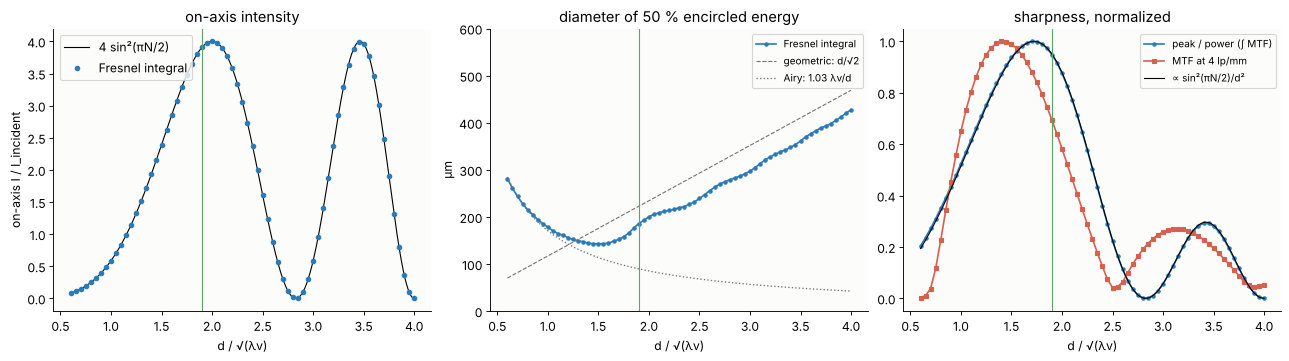

optimum d/sqrt(lambda v) by criterion (simulation | analytic):
  50 % encircled energy        1.45
  MTF at 4 lp/mm               1.40
  peak per power (= MTF area)  1.70 | 1.723  (tan x = 2x)
  on-axis intensity            2.00 | 2.000  (first Fresnel zone)
  geometric + Airy in quadrature    | 1.562  (Petzval, sqrt(2.44))
  Rayleigh 1891                     | 1.9    -> d = 315 µm


In [3]:
V = 50e3
S = np.sqrt(WL*V)                            # sqrt(lambda v) = 166 µm
xo = np.linspace(-700, 700, 281)             # 5 µm screen sampling
Xo, Yo = np.meshgrid(xo, xo)
Ro = np.hypot(Xo, Yo)
order = np.argsort(Ro.ravel())
r_sorted = Ro.ravel()[order]


def pinhole_psf(d, n=256):
    """Intensity on the screen behind a hole of diameter d, plane wave of intensity 1."""
    x = (np.arange(n) - n/2 + 0.5)*(1.08*d/n)
    X, Y = np.meshgrid(x, x)
    hole = (X**2 + Y**2 <= (d/2)**2).astype(complex)
    U, _, _ = fresnel_scaled(hole, x, x, V, WL, xo, xo)
    return np.abs(U)**2


q = np.linspace(0.6, 4.0, 69)                # d in units of sqrt(lambda v)
k_test = 4.0e-3                              # 4 lp/mm on the screen
fx = np.fft.fftfreq(len(xo), xo[1] - xo[0])
FX, FY = np.meshgrid(fx, fx)
ring = np.abs(np.hypot(FX, FY) - k_test) < 0.5*(fx[1] - fx[0])
rows = []
for qi in q:
    I = pinhole_psf(qi*S)
    P = I.sum()
    ee = np.cumsum(I.ravel()[order])/P
    mtf = np.abs(np.fft.fft2(I))/P
    rows.append((I[140, 140], 2*np.interp(0.5, ee, r_sorted), I[140, 140]/(P*(xo[1] - xo[0])**2),
                 mtf[ring].mean()))
I0, d50, peak_per_power, mtf_k = np.array(rows).T
q_fine = np.linspace(0.6, 4.0, 400)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), layout="constrained")
ax[0].plot(q_fine, ll.pinhole_on_axis_intensity(q_fine*S, WL, V), "k-", lw=1, label="4 sin²(πN/2)")
ax[0].plot(q, I0, "o", color=BLUE, ms=4, label="Fresnel integral")
ax[0].set_xlabel("d / √(λv)"); ax[0].set_ylabel("on-axis I / I_incident"); ax[0].legend()
ax[0].set_title("on-axis intensity")
ax[1].plot(q, d50, "o-", color=BLUE, ms=3, label="Fresnel integral")
blur, geo, diff = ll.pinhole_blur(q_fine*S, WL, V)
ax[1].plot(q_fine, geo/np.sqrt(2), "--", color=GREY, lw=1, label="geometric: d/√2")
ax[1].plot(q_fine, 1.03*WL*V/(q_fine*S), ":", color=GREY, lw=1.2, label="Airy: 1.03 λv/d")
ax[1].set_ylim(0, 600); ax[1].set_xlabel("d / √(λv)"); ax[1].set_ylabel("µm")
ax[1].set_title("diameter of 50 % encircled energy"); ax[1].legend(fontsize=9)
ax[2].plot(q, peak_per_power/peak_per_power.max(), "o-", color=BLUE, ms=3,
           label="peak / power (∫ MTF)")
ax[2].plot(q, mtf_k/mtf_k.max(), "s-", color=RED, ms=3, label="MTF at 4 lp/mm")
x_ = np.pi*q_fine**2/8
ax[2].plot(q_fine, (np.sin(x_)**2/q_fine**2)/(np.sin(x_)**2/q_fine**2).max(), "k-", lw=1,
           label="∝ sin²(πN/2)/d²")
ax[2].set_xlabel("d / √(λv)"); ax[2].set_title("sharpness, normalized"); ax[2].legend(fontsize=9)
for a in ax:
    a.axvline(1.9, color=GREEN, lw=1)
plt.show()

# optimum of the peak per transmitted power: maximize sin^2(x)/x, x = pi d^2/(8 lambda v)
x_opt = brentq(lambda x: np.tan(x) - 2*x, 0.5, 1.5)
q_peak_power = np.sqrt(8*x_opt/np.pi)
print("optimum d/sqrt(lambda v) by criterion (simulation | analytic):")
print("  50 % encircled energy        {:.2f}".format(q[np.argmin(d50)]))
print("  MTF at 4 lp/mm               {:.2f}".format(q[np.argmax(mtf_k)]))
print("  peak per power (= MTF area)  {:.2f} | {:.3f}  (tan x = 2x)".format(q[np.argmax(peak_per_power)], q_peak_power))
print("  on-axis intensity            {:.2f} | 2.000  (first Fresnel zone)".format(q[np.argmax(I0[:40])]))
print("  geometric + Airy in quadrature    | {:.3f}  (Petzval, sqrt(2.44))".format(np.sqrt(2.44)))
print("  Rayleigh 1891                     | 1.9    -> d = {:.0f} µm".format(ll.rayleigh_pinhole_diameter(WL, V)))

The on-axis intensity of the Fresnel integral follows $4\sin^2(\pi N/2)$
to plotting accuracy. Small holes give the Airy pattern of the far field
(the 50 % energy diameter approaches $1.03\,\lambda v/d$, the Airy value)
and large holes their own geometric shadow ($d/\sqrt 2$ for half the
energy of a uniform disk), with the familiar dark centres at two and four
Fresnel zones. In between lies a broad optimum, and where exactly depends
on what "sharp" means:

| criterion | optimum $d/\sqrt{\lambda v}$ |
|---|---|
| geometric and Airy diameter in quadrature (Petzval) | $\sqrt{2.44} = 1.56$ |
| smallest 50 % encircled energy | about 1.5 |
| peak intensity per transmitted power, i.e. the area under the MTF | 1.72 ($\tan x = 2x$) |
| Rayleigh (1891) | 1.9 |
| largest on-axis intensity (one full Fresnel zone) | 2.0 |

The peak per transmitted power is analytic too: the power through the hole
grows as $d^2$, the on-axis intensity as $\sin^2(\pi d^2/8\lambda v)$, and
their ratio peaks where $\tan x = 2x$. All criteria give a hole of about the
first Fresnel zone, and the sharpness changes by only some 10 % between 1.5
and 2. Rayleigh's 1.9 makes the path difference between the centre and the
rim of the hole $0.45\lambda$, a bright and well-defined core with a little
more light than the encircled-energy optimum. For an object at $u = 1$ m,
the optimum shrinks to $1.9\sqrt{\lambda z}$ with $z = (1/u + 1/v)^{-1}$
(printed below).

### Images through three pinholes

The PSFs of a hole of $0.8$, $1.9$ and $3.5\sqrt{\lambda v}$ blur a test
scene of a Siemens star and bars of 100, 150 and 220 µm period on the
screen. The printed numbers are the OTF at the bar frequencies.

Rayleigh pinhole for an object at 1 m: 307 µm, at infinity: 315 µm
d = 0.8 sqrt(lambda v): OTF at the bar periods 100 µm: +0.00, 150 µm: -0.00, 220 µm: +0.02
d = 1.9 sqrt(lambda v): OTF at the bar periods 100 µm: +0.05, 150 µm: +0.11, 220 µm: +0.18
d = 3.5 sqrt(lambda v): OTF at the bar periods 100 µm: +0.01, 150 µm: +0.04, 220 µm: -0.03


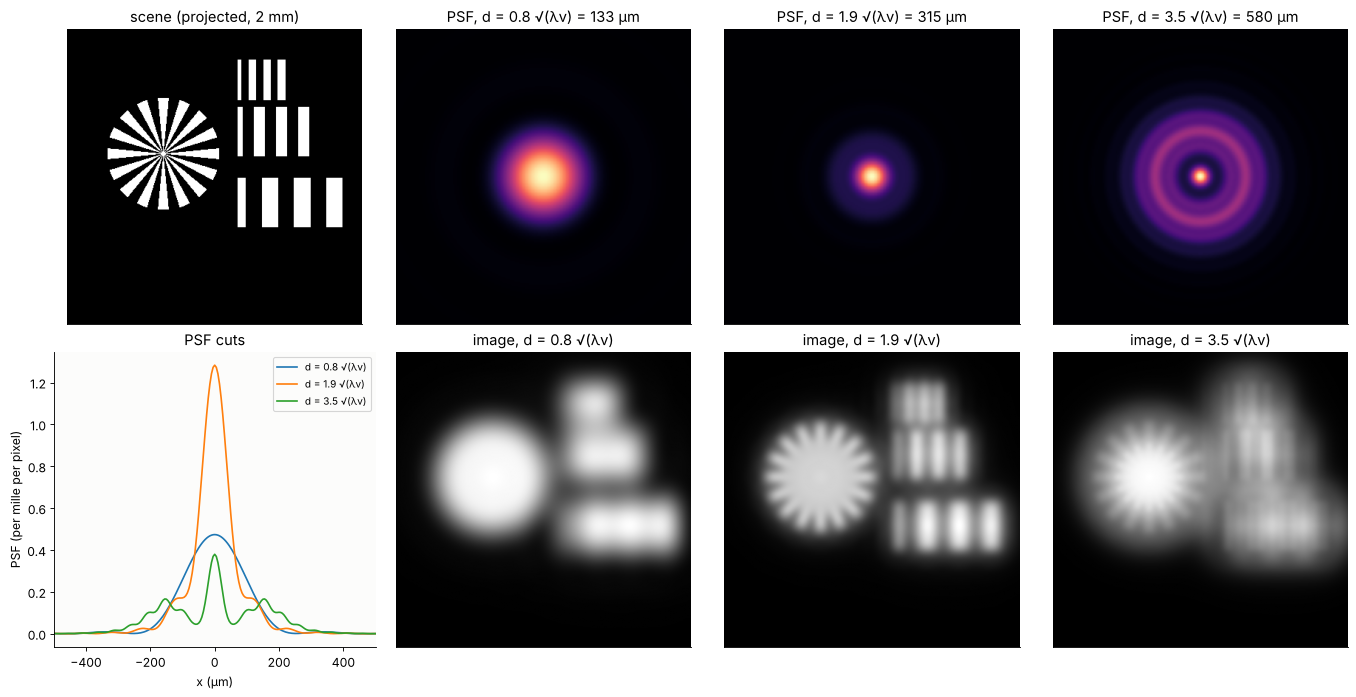

In [4]:
print("Rayleigh pinhole for an object at 1 m: {:.0f} µm, at infinity: {:.0f} µm".format(
    ll.rayleigh_pinhole_diameter(WL, V, 1e6), ll.rayleigh_pinhole_diameter(WL, V)))
qs = (0.8, 1.9, 3.5)
psfs = {qi: pinhole_psf(qi*S) for qi in qs}

# a test scene on the screen: Siemens star and bars (5 µm sampling, 2 mm field)
n_sc = 400
xs = (np.arange(n_sc) - n_sc/2)*5.0
XS, YS = np.meshgrid(xs, xs)
scene = siemens_star(XS, YS, -350, 150, 380, spokes=16)
BARS = ((100, 650), (150, 300), (220, -180))          # bar groups: period p (µm), height
for p, y0 in BARS:
    scene += (np.abs(YS - y0) < min(1.4*p, 170)) & (XS > 150) & (XS < 150 + 3.5*p) & (np.cos(2*np.pi*(XS - 150)/p) > 0)
scene = np.clip(scene, 0, 1)

fig, ax = plt.subplots(2, 4, figsize=(17, 8.6), layout="constrained")
ax[0, 0].imshow(scene, cmap="gray", extent=[xs[0], xs[-1], xs[0], xs[-1]])
ax[0, 0].set_title("scene (projected, 2 mm)")
for k, qi in enumerate(qs):
    I = psfs[qi]
    a = ax[0, k + 1]
    a.imshow(I/I.max(), cmap="magma", extent=[xo[0], xo[-1], xo[0], xo[-1]])
    a.set_title("PSF, d = {} √(λv) = {:.0f} µm".format(qi, qi*S))
    a.set_xlim(-500, 500); a.set_ylim(-500, 500)
    img = fftconvolve(scene, I/I.sum(), mode="same")
    ax[1, k + 1].imshow(img, cmap="gray", extent=[xs[0], xs[-1], xs[0], xs[-1]])
    ax[1, k + 1].set_title("image, d = {} √(λv)".format(qi))
    ax[1, 0].plot(xo, I[140]/I.sum()*1e3, label="d = {} √(λv)".format(qi))
    otf = np.real(np.fft.fft2(np.fft.ifftshift(I)))/I.sum()
    print("d = {} sqrt(lambda v): OTF at the bar periods ".format(qi) + ", ".join(
        "{} µm: {:+.2f}".format(p, otf[np.abs(np.hypot(FX, FY) - 1/p) < 0.5*(fx[1] - fx[0])].mean())
        for p, _ in BARS))
ax[1, 0].set_xlim(-500, 500); ax[1, 0].set_xlabel("x (µm)"); ax[1, 0].set_ylabel("PSF (per mille per pixel)")
ax[1, 0].legend(fontsize=9); ax[1, 0].set_title("PSF cuts")
for a in list(ax[0]) + list(ax[1, 1:]):
    a.set_xticks([]); a.set_yticks([])
plt.show()

The small hole is in the far field: its OTF is that of a circular pupil
with the cutoff $d/\lambda v$, i.e. a period of $\lambda v/d = 206$ µm, so
even the coarsest bars are just gone. Rayleigh's hole passes all three bar
groups (cutoff near 87 µm in the far-field estimate), with 18 % contrast
at 220 µm. The large hole makes a sharp-edged disk of 580 µm with a bright
centre and rings (3.5 Fresnel zones); its OTF changes sign, and the
220 µm bars come out with reversed contrast, like a defocused lens.

A pinhole camera at $v = 50$ mm thus resolves about 0.1 to 0.2 mm on the
screen: a "lens" of focal length 50 mm at $f/160$, stopped down until
diffraction and the hole size are equal. The light through the hole is
$(d/v)^2\pi/4 \approx 3\cdot 10^{-5}$ of the light through a fully open
50 mm aperture. That is why the next idea is to open many holes.

## 2. The coded aperture

### Setup

X-ray and gamma-ray telescopes cannot use lenses, and a pinhole wastes
almost all photons. A **coded aperture** opens half of a mask: every source
casts a shadow of the whole mask onto the detector, shifted by its
direction, and the detector records the sum of all shadows. For a mask
that is mosaicked $2\times 2$ in front of a detector of $p\times p$ elements
(one element per mask element), every source in the fully coded field of
view casts a *cyclically* shifted copy of the mask, and the picture is the
periodic convolution $D = O \circledast A$ of the scene $O$ with the mask
$A$ (`ll.coded_aperture_image()`).

A **modified uniformly redundant array** (MURA, Gottesman and Fenimore
1989) is a mask whose periodic correlation with a decoding array
$G = 2A - 1$ (with $G_{00} = +1$) is a perfect delta:
$A \star G = \frac{p^2-1}{2}\,\delta$. Decoding is then a single
correlation, $\hat O = D \star G\,/\,n_\text{open}$
(`ll.coded_aperture_decode()`), and it is exact.

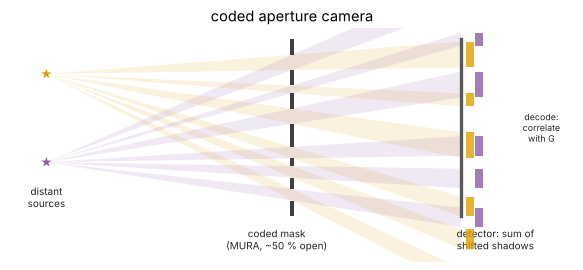

MURA orders up to 70: [5, 13, 17, 29, 37, 41, 53, 61]
p = 61: 1860 of 3721 elements open (49.99 %), sum of G = 1
A * G: peak 1860, largest sidelobe 1.8e-13


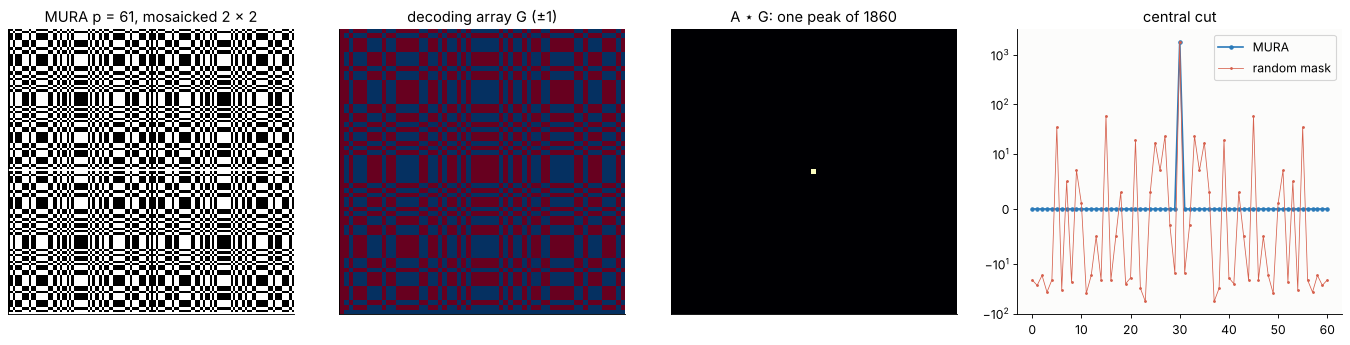

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.8))
sketch.lensless_camera(ax, "coded", title="coded aperture camera")
plt.show()

P = 61
A = ll.mura(P)
G = ll.mura_decoder(A)
N_OPEN = (P*P - 1)//2
corr = np.real(np.fft.ifft2(np.fft.fft2(A)*np.conj(np.fft.fft2(G))))
print("MURA orders up to 70:", ll.mura_orders(70))
print("p = {}: {} of {} elements open ({:.2f} %), sum of G = {}".format(
    P, A.sum(), P*P, 100*A.mean(), G.sum()))
print("A * G: peak {:.0f}, largest sidelobe {:.1e}".format(corr[0, 0], np.abs(corr.ravel()[1:]).max()))
# for comparison: a random mask with the same open fraction
rng = np.random.default_rng(7)
A_rand = (rng.random((P, P)) < 0.5).astype(int)
corr_rand = np.real(np.fft.ifft2(np.fft.fft2(A_rand)*np.conj(np.fft.fft2(2*A_rand - 1))))

fig, ax = plt.subplots(1, 4, figsize=(17, 4.2), layout="constrained")
ax[0].imshow(np.tile(A, (2, 2)), cmap="gray_r", interpolation="nearest")
ax[0].set_title("MURA p = 61, mosaicked 2 x 2")
ax[1].imshow(G, cmap="RdBu_r", interpolation="nearest")
ax[1].set_title("decoding array G (±1)")
ax[2].imshow(np.fft.fftshift(corr), cmap="magma", interpolation="nearest")
ax[2].set_title("A ⋆ G: one peak of {}".format(N_OPEN))
ax[3].plot(np.fft.fftshift(corr)[P//2], "o-", ms=3, color=BLUE, label="MURA")
ax[3].plot(np.fft.fftshift(corr_rand)[P//2], ".-", ms=3, color=RED, lw=0.7, label="random mask")
ax[3].set_yscale("symlog", linthresh=10); ax[3].legend(); ax[3].set_title("central cut")
for a in ax[:3]:
    a.set_xticks([]); a.set_yticks([])
plt.show()

All sidelobes of the MURA correlation vanish to rounding, while a random
mask with the same open fraction leaves sidelobes of order
$\sqrt{p^2/2} \approx 40$ around its peak, an artefact that would add to
every decoded image.

### Images at the same exposure

Two scenes, both of $61\times 61$ elements, recorded with photon (Poisson)
noise by a single hole of one mask element and by the MURA in the same
exposure, i.e. with $n_\text{open} = 1860$ times more light: a sparse field
of stars, the brightest one sending 4 photons through a single element,
and an extended object of the same peak brightness that fills about a
third of the field.

stars           :  0.4 % of the field lit; noise on the lit elements: single hole 0.95, MURA 0.10 (Fenimore: sqrt(psi_T/n_open) = 0.13); mean SNR of the lit elements: 1.3 vs 15.8
extended object : 27.4 % of the field lit; noise on the lit elements: single hole 1.97, MURA 1.44 (Fenimore: sqrt(psi_T/n_open) = 1.48); mean SNR of the lit elements: 2.0 vs 2.7


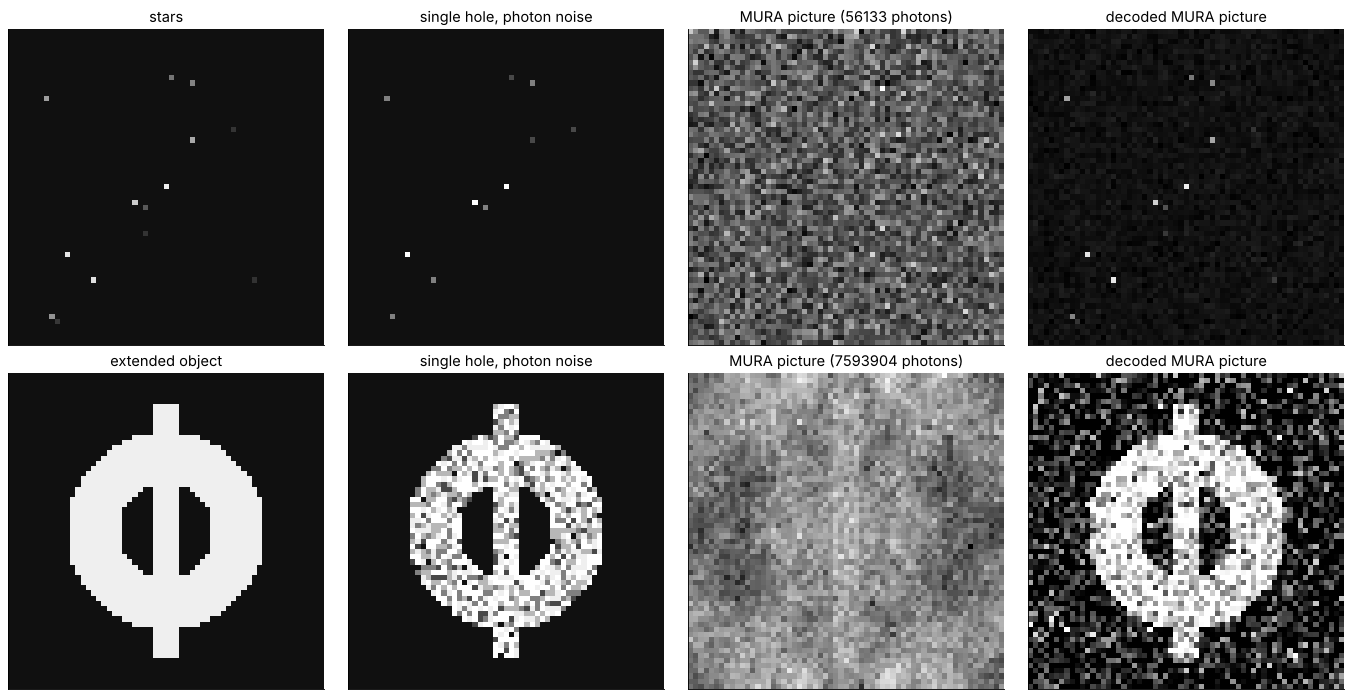

In [6]:
yy, xx = np.mgrid[0:P, 0:P]
stars = np.zeros((P, P))
rng = np.random.default_rng(3)
pos = rng.integers(3, P - 3, (14, 2))
stars[pos[:, 0], pos[:, 1]] = 4.0*rng.random(14)**1.5
stars[30, 30] = 4.0
extended = 4.0*(np.hypot(xx - 30, yy - 30) < 19) - 4.0*(np.hypot(xx - 30, yy - 30) < 9) \
    + 4.0*((np.abs(xx - 30) < 3) & (np.abs(yy - 30) < 25))
extended = np.clip(extended, 0, 4)
poisson = CameraNoiser("poisson", rng=11)

fig, ax = plt.subplots(2, 4, figsize=(17, 8.6), layout="constrained")
for row, (name, sc) in enumerate((("stars", stars), ("extended object", extended))):
    pin = poisson(sc)
    picture = poisson(ll.coded_aperture_image(sc, A))
    dec = ll.coded_aperture_decode(picture, G)
    for col, (img, title) in enumerate(((sc, name), (pin, "single hole, photon noise"),
                                        (picture, "MURA picture ({:.0f} photons)".format(picture.sum())),
                                        (dec, "decoded MURA picture"))):
        ax[row, col].imshow(img, cmap="gray", interpolation="nearest",
                            vmin=None if col == 2 else -0.3, vmax=None if col == 2 else 4.3)
        ax[row, col].set_title(title); ax[row, col].set_xticks([]); ax[row, col].set_yticks([])
    lit = sc > 0
    print("{:16s}: {:4.1f} % of the field lit; noise on the lit elements: single hole {:.2f}, "
          "MURA {:.2f} (Fenimore: sqrt(psi_T/n_open) = {:.2f}); mean SNR of the lit elements: "
          "{:.1f} vs {:.1f}".format(
              name, 100*lit.mean(), np.std((pin - sc)[lit]), np.std((dec - sc)[lit]),
              np.sqrt(sc.sum()/N_OPEN), np.mean(ll.pinhole_snr(sc[lit])),
              np.mean(ll.coded_aperture_snr(sc[lit], sc.sum(), N_OPEN))))
plt.show()

The MURA picture of the stars looks like noise; decoded, every star is
there, with an SNR about twelve times that of the single hole and its
handful of photons. For the extended object, which lights a quarter of the
field, the decoded picture is hardly better than the single hole, although
the MURA recorded 1860 times more photons.

The reason is in the decoding. Every decoded element is a sum over *all*
detector elements, with weights $\pm 1$, so it collects the photon noise of
all sources. Fenimore (1978) worked out the signal-to-noise ratio of a
scene element $j$: with $\psi_j$ photons per open element from it, the
total $\psi_T = \sum_k\psi_k$ and a background of $B$ per detector element,

$$\mathrm{SNR}_j = \frac{n_\text{open}\,\psi_j}{\sqrt{n_\text{open}\psi_T + p^2 B}}
\quad\text{vs.}\quad \mathrm{SNR}_j^\text{hole} = \frac{\psi_j}{\sqrt{\psi_j + B}}$$

(`ll.coded_aperture_snr()`, `ll.pinhole_snr()`). The noise of every decoded
element is the same, $\sqrt{\psi_T/n_\text{open}}$ for $B = 0$, which is
the rms error printed above. A single point source gains
$\sqrt{n_\text{open}} = 43$ in SNR; a source among others gains only
$\sqrt{n_\text{open}\psi_j/\psi_T}$, which drops below one when the other
sources outshine it by more than $n_\text{open}$ in total.

### SNR against the filling of the field

Scenes with one point of interest and $K$ further elements of the same
brightness, $\psi = 2$ photons per open element, without and with a
background of $B = 2$, 1000 noise realizations each.

B = 0: SNR MURA (MC/Fenimore) at K+1 = 1: 61.1/61.0, at K+1 = 3001: 1.12/1.11


B = 2: SNR MURA (MC/Fenimore) at K+1 = 1: 34.0/35.2, at K+1 = 3001: 1.09/1.11


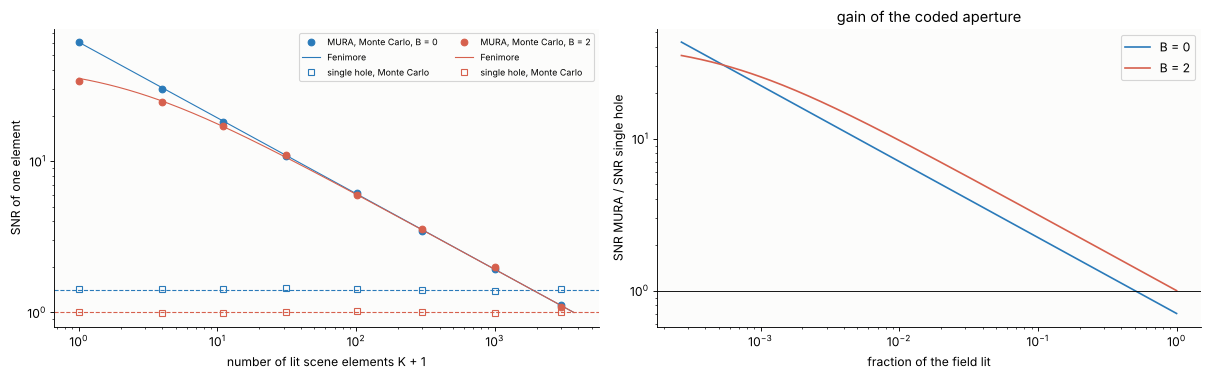

In [7]:
psi = 2.0
Ks = np.array([0, 3, 10, 30, 100, 300, 1000, 3000])
rng = np.random.default_rng(5)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for B, col in ((0.0, BLUE), (2.0, RED)):
    snr_mc, snr_pin_mc = [], []
    for K in Ks:
        sc = np.zeros(P*P)
        others = rng.choice(np.arange(1, P*P), K, replace=False)
        sc[0] = psi
        sc[others] = psi
        sc = sc.reshape(P, P)
        expected = ll.coded_aperture_image(sc, A) + B
        est = np.array([ll.coded_aperture_decode(rng.poisson(expected), G)[0, 0] for _ in range(1000)])
        snr_mc.append((est.mean() - B/N_OPEN)/est.std())
        pin = rng.poisson(psi + B, 4000)
        snr_pin_mc.append(psi/pin.std())
    K_f = np.logspace(0, np.log10(P*P), 200) - 1
    ax[0].plot(Ks + 1, snr_mc, "o", color=col, label="MURA, Monte Carlo, B = {:g}".format(B))
    ax[0].plot(K_f + 1, ll.coded_aperture_snr(psi, psi*(K_f + 1), N_OPEN, B, P*P), "-", color=col, lw=1,
               label="Fenimore")
    ax[0].plot(Ks + 1, snr_pin_mc, "s", color=col, mfc="none", label="single hole, Monte Carlo")
    ax[0].axhline(ll.pinhole_snr(psi, B), color=col, ls="--", lw=1)
    ratio = ll.coded_aperture_snr(psi, psi*(K_f + 1), N_OPEN, B, P*P)/ll.pinhole_snr(psi, B)
    ax[1].plot((K_f + 1)/(P*P), ratio, color=col, label="B = {:g}".format(B))
    print("B = {:g}: SNR MURA (MC/Fenimore) at K+1 = 1: {:.1f}/{:.1f}, at K+1 = {}: {:.2f}/{:.2f}".format(
        B, snr_mc[0], ll.coded_aperture_snr(psi, psi, N_OPEN, B, P*P), Ks[-1] + 1, snr_mc[-1],
        ll.coded_aperture_snr(psi, psi*(Ks[-1] + 1), N_OPEN, B, P*P)))
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("number of lit scene elements K + 1"); ax[0].set_ylabel("SNR of one element")
ax[0].legend(fontsize=8, ncol=2)
ax[1].axhline(1, color="k", lw=0.8)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("fraction of the field lit"); ax[1].set_ylabel("SNR MURA / SNR single hole")
ax[1].legend(); ax[1].set_title("gain of the coded aperture")
plt.show()

The Monte Carlo SNRs lie on Fenimore's curves. For a lone point the coded
aperture is 43 times better; with half the field lit, $\psi_T \approx
n_\text{open}\psi_j$, the advantage is gone, and a fully lit field is
$\sqrt 2$ worse than a single hole. A background helps the coded aperture
relatively, since the single hole suffers from it as well while the coded
camera spreads it over all elements: with $B = \psi$ the break-even moves
to a fully lit field. Coded apertures are therefore at their best for what
they were invented for: a few bright X-ray or gamma sources on a dark, noisy
sky (and for weak point sources in nuclear medicine), not for daylight
scenes.

### Diffraction: how small can the mask elements be?

The shadow model holds only as long as diffraction does not blur the
shadow of one mask element. With elements of width $a$ at the distance
$z$ from the detector, that requires a Fresnel number
$N_F = a^2/(\lambda z) \gtrsim 1$: the same $\sqrt{\lambda z}$ as for the
pinhole. Below, a plane wave (a source on the axis) passes a $2\times 2$
mosaic of a $p = 13$ MURA with $a = 20$ µm, is propagated with the angular
spectrum method, integrated over the $13\times 13$ detector elements and
decoded.

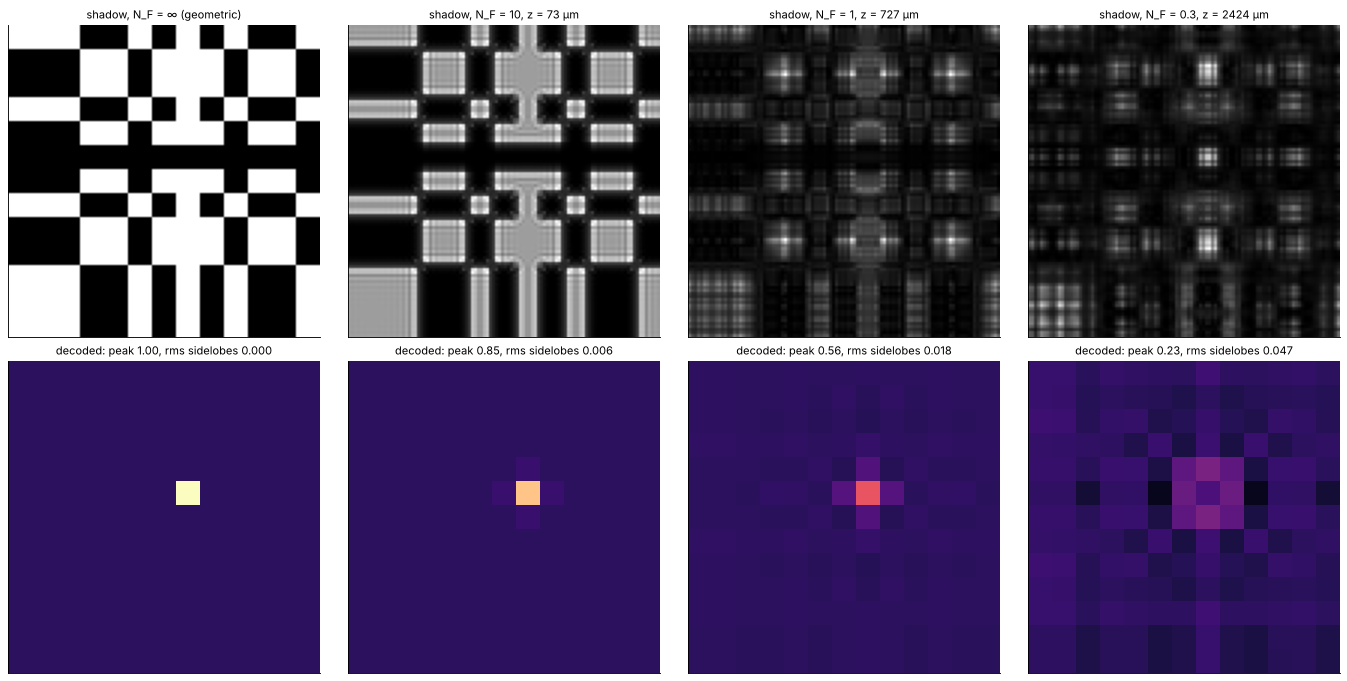

In [8]:
p_small, a_el, os_ = 13, 20.0, 8              # MURA order, element (µm), samples per element
A13, G13 = ll.mura(p_small), ll.mura_decoder(ll.mura(p_small))
n_grid = 1024
dx = a_el/os_
x, y, X, Y = grid2d(-n_grid*dx/2, n_grid*dx/2, -n_grid*dx/2, n_grid*dx/2, n_grid)
mosaic = np.kron(np.tile(A13, (2, 2)), np.ones((os_, os_)))
mask = np.zeros((n_grid, n_grid))
c0 = n_grid//2 - p_small*os_
mask[c0:c0 + 2*p_small*os_, c0:c0 + 2*p_small*os_] = mosaic
start = c0 + (p_small//2)*os_                  # detector: the central p x p elements of the shadow

fig, ax = plt.subplots(2, 4, figsize=(17, 8.4), layout="constrained")
for k, NF in enumerate((np.inf, 10.0, 1.0, 0.3)):
    if np.isinf(NF):
        I = mask
    else:
        z = a_el**2/(WL*NF)
        U, _, _ = rayleigh_sommerfeld_I_TF(mask.astype(complex), x, y, z, WL)
        I = np.abs(U)**2
    det = I[start:start + p_small*os_, start:start + p_small*os_]
    D = det.reshape(p_small, os_, p_small, os_).mean(axis=(1, 3))
    dec = ll.coded_aperture_decode(D, G13)
    dec = np.roll(dec, (-(p_small//2), -(p_small//2)), axis=(0, 1))   # source on the axis -> element 0
    dec = np.fft.fftshift(dec)
    ax[0, k].imshow(det, cmap="gray", extent=[0, p_small*a_el, 0, p_small*a_el])
    ax[0, k].set_title("shadow, N_F = {}".format("∞ (geometric)" if np.isinf(NF) else
                                                  "{:g}, z = {:.0f} µm".format(NF, a_el**2/(WL*NF)))
                       , fontsize=10)
    ax[1, k].imshow(dec, cmap="magma", interpolation="nearest", vmin=-0.2, vmax=1)
    side = np.delete(dec.ravel(), np.argmax(dec))
    ax[1, k].set_title("decoded: peak {:.2f}, rms sidelobes {:.3f}".format(dec.max(), side.std()), fontsize=10)
    for a in (ax[0, k], ax[1, k]):
        a.set_xticks([]); a.set_yticks([])
plt.show()

At $N_F = 10$ the shadow edges show Fresnel fringes, and the decoded point
keeps 85 % of its height. At $N_F = 1$ the shadow of every element is
blurred over about its own width, the peak drops to about half, and the
missing light reappears as structured sidelobes around it. At
$N_F = 0.3$ the shadow is a diffraction pattern and the decoded image is
mostly artefacts. For visible light and a mask a few millimetres from the
sensor this limits the elements to some 50 µm, i.e. to a coarse resolution. The
optical lensless cameras that work around this use the diffraction
instead of fighting it: they calibrate the actual PSF, whatever it looks
like, and deconvolve. That is the diffuser camera.

## 3. The diffuser camera

### Setup

DiffuserCam (Antipa et al. 2018) puts a smooth random phase plate, an
off-the-shelf engineered diffuser, a few millimetres in front of a bare
image sensor. Its bumps are weak random lenslets; their rays cross on the
sensor in a network of bright lines, the **caustics**. The PSF is this
network: large, spread over the whole sensor, but with sharp features
in all directions, so its transfer function stays high up to high
spatial frequencies, unlike the blur of a pinhole that is too large.

Two geometric properties make the PSF usable:

- A point source at the lateral position $s$ and the distance $u$ shifts the
  pattern by $-s z/u$ (the rays through the centre of the plate are not
  deflected on average). Within the field of view the picture is therefore a
  convolution of the scene with one PSF.
- The pattern is the shadow of the plate's features cast by the point
  source, magnified by $(u+z)/u = 1 + z/u$ (`ll.psf_magnification()`). A
  source at another distance gives the same PSF, rescaled. One calibration
  at one depth gives the PSF for every depth (`ll.scale_psf()`).

The diffuser here is a Gaussian random phase with a correlation length of
$\ell = 90$ µm and $\sigma = 5.5$ rad (an rms height of about 1 µm for
$n = 1.5$), in a circular aperture of 1.5 mm, $z = 4.5$ mm in front of the
sensor. The PSF of a point at the distance $u$ is computed with
`ll.point_source_psf()`: the spherical wave times the diffuser, propagated
with the angular spectrum method, on a $1024^2$ grid of 3 µm, then binned to
6 µm sensor pixels.

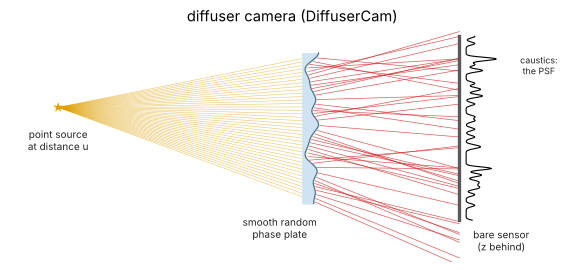

estimated focal length of the bumps: 4.9 mm, sensor at z = 4.5 mm


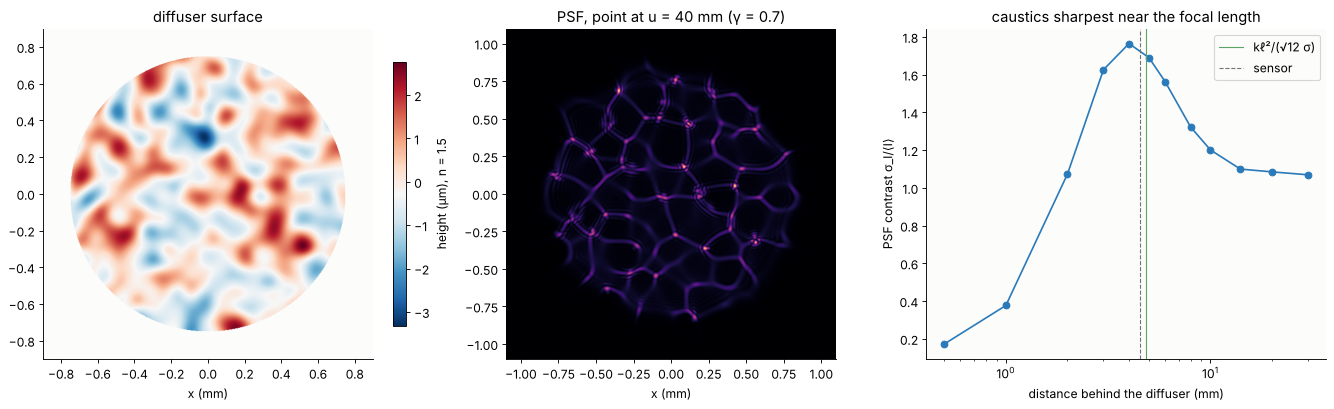

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
sketch.lensless_camera(ax, "diffuser", title="diffuser camera (DiffuserCam)")
plt.show()

N_D, DX_D, Z_D = 1024, 3.0, 4500.0
ELL, SIGMA = 90.0, 5.5
xd, yd, XD, YD = grid2d(-N_D*DX_D/2, N_D*DX_D/2, -N_D*DX_D/2, N_D*DX_D/2, N_D)
phase = random_phase_screen((N_D, N_D), ELL, SIGMA, dx=DX_D, rng=1)
aperture = np.hypot(XD, YD) <= 750.0
diffuser = aperture*np.exp(1j*phase)


def bin2(a):
    return a.reshape(a.shape[0]//2, 2, a.shape[1]//2, 2).sum(axis=(1, 3))


def psf_at(u, s=0.0, z=Z_D):
    return bin2(ll.point_source_psf(diffuser, xd, yd, z, WL, u, source_x=s))


U1 = 40e3
psf1 = psf_at(U1)
f_c = ll.caustic_distance(ELL, SIGMA, WL)
print("estimated focal length of the bumps: {:.1f} mm, sensor at z = {:.1f} mm".format(f_c/1e3, Z_D/1e3))

# PSF contrast (std/mean inside the aperture shadow) against the distance behind the plate
zs = np.array([0.5, 1, 2, 3, 4, 5, 6, 8, 10, 14, 20, 30])*1e3
contrast = []
inner = np.hypot(XD, YD) < 500
for z in zs:
    I = ll.point_source_psf(diffuser, xd, yd, z, WL, np.inf)
    contrast.append(I[inner].std()/I[inner].mean())

xs_d = (np.arange(N_D//2) - N_D//4)*2*DX_D        # 6 µm sensor pixels
ext = [xs_d[0]/1e3, xs_d[-1]/1e3, xs_d[0]/1e3, xs_d[-1]/1e3]
fig, ax = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
h = phase*WL/(2*np.pi*0.5)
im = ax[0].imshow(np.where(aperture, h, np.nan), cmap="RdBu_r",
                  extent=[xd[0]/1e3, xd[-1]/1e3, yd[0]/1e3, yd[-1]/1e3])
ax[0].set_xlim(-0.9, 0.9); ax[0].set_ylim(-0.9, 0.9)
plt.colorbar(im, ax=ax[0], label="height (µm), n = 1.5", shrink=0.8)
ax[0].set_title("diffuser surface"); ax[0].set_xlabel("x (mm)")
ax[1].imshow(psf1**0.7, cmap="magma", extent=ext)
ax[1].set_xlim(-1.1, 1.1); ax[1].set_ylim(-1.1, 1.1)
ax[1].set_title("PSF, point at u = 40 mm (γ = 0.7)"); ax[1].set_xlabel("x (mm)")
ax[2].plot(zs/1e3, contrast, "o-", color=BLUE)
ax[2].axvline(f_c/1e3, color=GREEN, lw=1, label="kℓ²/(√12 σ)")
ax[2].axvline(Z_D/1e3, color=GREY, ls="--", lw=1, label="sensor")
ax[2].set_xscale("log"); ax[2].set_xlabel("distance behind the diffuser (mm)")
ax[2].set_ylabel("PSF contrast σ_I/⟨I⟩"); ax[2].legend(); ax[2].set_title("caustics sharpest near the focal length")
plt.show()

The PSF contrast rises from the smooth near field, peaks where the bumps
come to their foci, and falls slowly beyond, where the caustics of
neighbouring bumps overlap and the pattern turns into speckle-like
interference. The peak, at about 4 mm, lies close to the estimate
$f = k\ell^2/(\sqrt{12}\,\sigma) = 4.9$ mm from the rms curvature of the
random surface (`ll.caustic_distance()`); the strongest bumps, which make
the brightest lines, focus earlier than the typical one. The sensor at
4.5 mm sits on the peak, where the caustic lines are thin and not yet
broken up by interference.

### Shift and scaling of the PSF

The PSF of a point 2 mm off the axis is compared with the shifted
on-axis PSF; the PSFs of points at 80 and 160 mm with the PSF at 40 mm
rescaled by $(1 + z/u)/(1 + z/u_1)$.

shift for s = 2 mm: [   0. -228.] µm, expected -s z/u = -225 µm; correlation with the shifted on-axis PSF 0.975


u =  80 mm: best scale 0.9500, (1 + z/u)/(1 + z/u1) = 0.9494, correlation scaled 0.991, unscaled 0.453


u = 160 mm: best scale 0.9240, (1 + z/u)/(1 + z/u1) = 0.9242, correlation scaled 0.983, unscaled 0.333


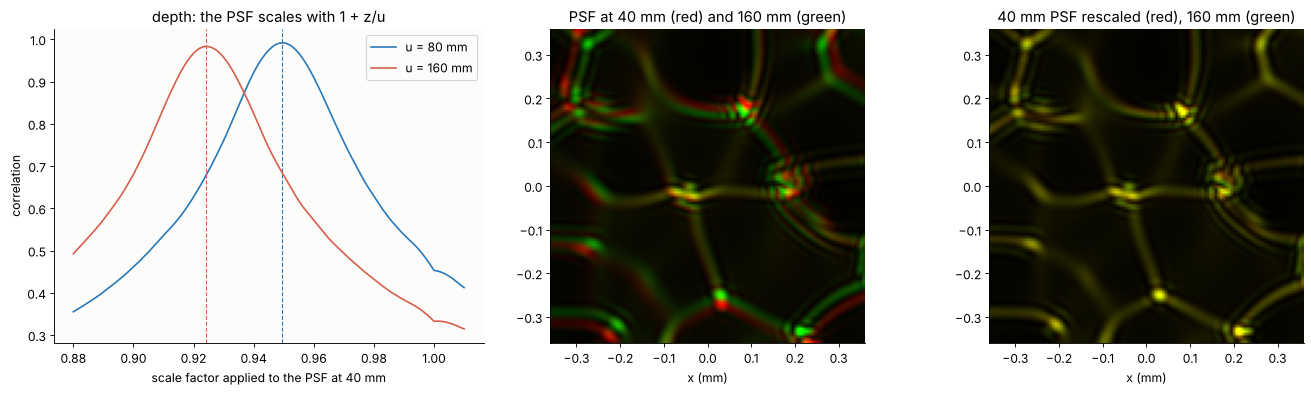

In [10]:
psf_shift = psf_at(U1, s=2000.0)
C = np.real(np.fft.ifft2(np.fft.fft2(psf_shift)*np.conj(np.fft.fft2(psf1))))
iy, ix = np.unravel_index(np.argmax(C), C.shape)
n2 = psf1.shape[0]
shift = np.array([(iy + n2//2) % n2 - n2//2, (ix + n2//2) % n2 - n2//2])*2*DX_D
print("shift for s = 2 mm: {} µm, expected -s z/u = {:.0f} µm; correlation with the shifted "
      "on-axis PSF {:.3f}".format(shift, -2000*Z_D/U1, C.max()/np.sqrt(np.sum(psf1**2)*np.sum(psf_shift**2))))


def ncc(a, b):
    a, b = a - a.mean(), b - b.mean()
    return np.sum(a*b)/np.sqrt(np.sum(a*a)*np.sum(b*b))


factors = np.linspace(0.88, 1.01, 131)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
for u, col in ((80e3, BLUE), (160e3, RED)):
    psf_u = psf_at(u)
    c = [ncc(ll.scale_psf(psf1, f), psf_u) for f in factors]
    expected = ll.psf_magnification(Z_D, u)/ll.psf_magnification(Z_D, U1)
    ax[0].plot(factors, c, color=col, label="u = {:.0f} mm".format(u/1e3))
    ax[0].axvline(expected, color=col, ls="--", lw=1)
    print("u = {:3.0f} mm: best scale {:.4f}, (1 + z/u)/(1 + z/u1) = {:.4f}, correlation scaled {:.3f}, "
          "unscaled {:.3f}".format(u/1e3, factors[np.argmax(c)], expected, max(c), ncc(psf1, psf_u)))
    if u == 160e3:
        psf_far = psf_u
ax[0].set_xlabel("scale factor applied to the PSF at 40 mm"); ax[0].set_ylabel("correlation")
ax[0].legend(); ax[0].set_title("depth: the PSF scales with 1 + z/u")
crop = slice(n2//2 - 60, n2//2 + 60)
rgb = np.zeros((120, 120, 3))
rgb[..., 0] = psf1[crop, crop]/psf1[crop, crop].max()
rgb[..., 1] = psf_far[crop, crop]/psf_far[crop, crop].max()
ax[1].imshow(np.clip(1.6*rgb, 0, 1)**0.8, extent=[-0.36, 0.36, -0.36, 0.36])
ax[1].set_title("PSF at 40 mm (red) and 160 mm (green)"); ax[1].set_xlabel("x (mm)")
scaled = ll.scale_psf(psf1, ll.psf_magnification(Z_D, 160e3)/ll.psf_magnification(Z_D, U1))
rgb[..., 0] = scaled[crop, crop]/scaled[crop, crop].max()
ax[2].imshow(np.clip(1.6*rgb, 0, 1)**0.8, extent=[-0.36, 0.36, -0.36, 0.36])
ax[2].set_title("40 mm PSF rescaled (red), 160 mm (green)"); ax[2].set_xlabel("x (mm)")
plt.show()

The off-axis PSF is the on-axis one shifted by $-sz/u$ to within one
pixel (correlation 0.975), and the best rescaling of the 40 mm PSF onto the
80 and 160 mm PSFs agrees with $(1+z/u)/(1+z/u_1)$ to 0.1 %, with
correlations of 0.98 to 0.99 against 0.3 to 0.45 without the rescaling. Away from the centre, the
unscaled patterns of two depths drift apart (red and green separate);
rescaled, they overlap (yellow). The remaining difference is real: the
caustics of the farther source focus a little closer to the plate, so the
lines are not exactly as sharp.

### Reconstruction of a 2D scene

The scene (a Siemens star, text and a grey square) sits at $u = 40$ mm. In
the coordinates of the sensor, magnified by $-z/u$, the picture is the
convolution of the scene with the PSF, recorded with photon noise
(2000 photons in the brightest pixel) on a sensor of $256\times 256$
pixels (1.5 mm), while the PSF and the blurred scene extend over twice that
width. Three reconstructions:

- **Wiener** deconvolution (`ll.wiener_deconvolve()`) of a picture from a
  sensor large enough to catch everything ($512\times 512$),
- Wiener deconvolution of the real, cropped picture, padded with zeros,
- **ADMM** with total variation and positivity on the cropped picture
  (`ll.admm_tv_deconvolve()`): the crop is part of the forward model
  $b = C\,(h * x)$, so the solver fills in what the sensor did not see
  from the parts of the PSF that it did.

deconvolutions: 10.9 s
Wiener, full sensor      relative error 0.61
Wiener, cropped sensor   relative error 0.88
ADMM-TV, cropped sensor  relative error 0.32


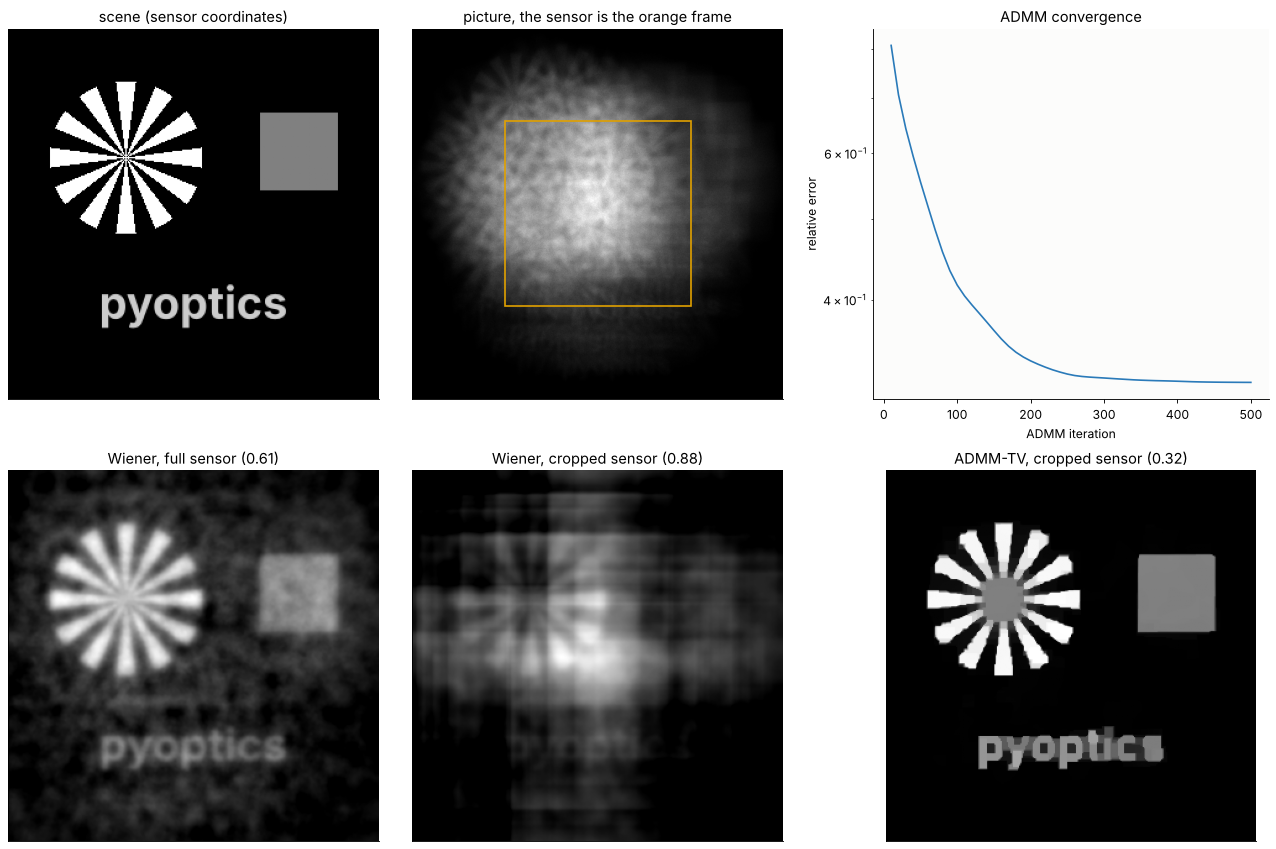

In [11]:
n_s = n2
jj, ii = np.meshgrid(np.arange(n_s) - n_s//2, np.arange(n_s) - n_s//2)
scene2d = siemens_star(jj, ii, -55, 45, 62, spokes=12)
scene2d += 0.8*text_image("pyoptics", n_s, 26, y=0.36)
scene2d += 0.5*((np.abs(jj - 85) < 32) & (np.abs(ii - 50) < 32))
scene2d = np.clip(scene2d, 0, 1)
SENSOR = (256, 256)

clean_full = ll.convolve_crop(scene2d, psf1)
scale = Scaler(2000.0)
photons = CameraNoiser("poisson", rng=21)
b_full = photons(scale(clean_full))*clean_full.max()/2000
b_crop = photons(scale(ll.convolve_crop(scene2d, psf1, SENSOR)))*clean_full.max()/2000
b_pad = np.zeros_like(scene2d)
b_pad[ll._crop_slices(scene2d.shape, SENSOR)] = b_crop

roi = (np.abs(jj) < 150) & (np.abs(ii) < 150)


def rel_error(x):
    """Relative rms error in the region of the scene, after the best scaling."""
    a, c = x[roi], scene2d[roi]
    return np.linalg.norm((a @ c)/(a @ a)*a - c)/np.linalg.norm(c)


t0 = time.time()
recs = {"Wiener, full sensor": ll.wiener_deconvolve(b_full, psf1, 3e-3),
        "Wiener, cropped sensor": ll.wiener_deconvolve(b_pad, psf1, 1e-2)}
history = []
recs["ADMM-TV, cropped sensor"] = ll.admm_tv_deconvolve(
    b_crop, psf1, tau=1e-4, n_iter=500,
    callback=lambda i, x: history.append(rel_error(x)) if i % 10 == 9 else None)
print("deconvolutions: {:.1f} s".format(time.time() - t0))
for k, v in recs.items():
    print("{:24s} relative error {:.2f}".format(k, rel_error(v)))

fig, ax = plt.subplots(2, 3, figsize=(16, 10.5), layout="constrained")
view = slice(n_s//2 - 150, n_s//2 + 150)
ax[0, 0].imshow(scene2d[view, view], cmap="gray"); ax[0, 0].set_title("scene (sensor coordinates)")
ax[0, 1].imshow(b_full, cmap="gray")
ax[0, 1].add_patch(plt.Rectangle((n_s//2 - 128, n_s//2 - 128), 256, 256, fill=False, ec=ORANGE, lw=1.5))
ax[0, 1].set_title("picture, the sensor is the orange frame")
ax[0, 2].semilogy(10*np.arange(1, len(history) + 1), history, color=BLUE)
ax[0, 2].set_xlabel("ADMM iteration"); ax[0, 2].set_ylabel("relative error"); ax[0, 2].set_title("ADMM convergence")
for a, (k, v) in zip(ax[1], recs.items()):
    a.imshow(np.clip(v[view, view], 0, None), cmap="gray")
    a.set_title("{} ({:.2f})".format(k, rel_error(v)))
for a in list(ax[0, :2]) + list(ax[1]):
    a.set_xticks([]); a.set_yticks([])
plt.show()

The picture on the sensor shows nothing of the scene, only a smeared
caustic pattern. With the full picture, Wiener deconvolution recovers the
scene, blurred and with a grainy background: noise amplified at the
frequencies where the OTF is weak, balanced against the blur by the
regularization. With the real sensor, the picture is cut off where the PSF of the
outer scene points leaves the sensor, and Wiener's periodic deconvolution
produces mostly artefacts from the sharp edges of the crop. ADMM
models the crop and is
not bothered by it; the total variation term suppresses the noise in the
flat regions and keeps the edges, which suits this piecewise constant
scene particularly well (relative errors 0.32 against 0.61 and 0.88). The
centre of the Siemens star, where the spokes are finer than the caustic
lines, comes out as a grey disk: the resolution is set by the width of
the lines and the noise.

### Refocusing: two objects at different distances

Now the Siemens star is at $u_1 = 40$ mm and the text at $u_2 = 120$ mm.
Each is blurred with the PSF of its own depth, here computed with the
wave model; the reconstructions only know the 40 mm calibration and
rescale it with $1 + z/u$ to every depth they try. (In the scene
coordinates of the sensor both objects are already magnified by $z/u$;
the text is three times smaller in object space than it appears.)

sharpest depth: star 40 mm (true 40), text 120 mm (true 120)
correlation of the computed 120 mm PSF with the rescaled 40 mm PSF: 0.987


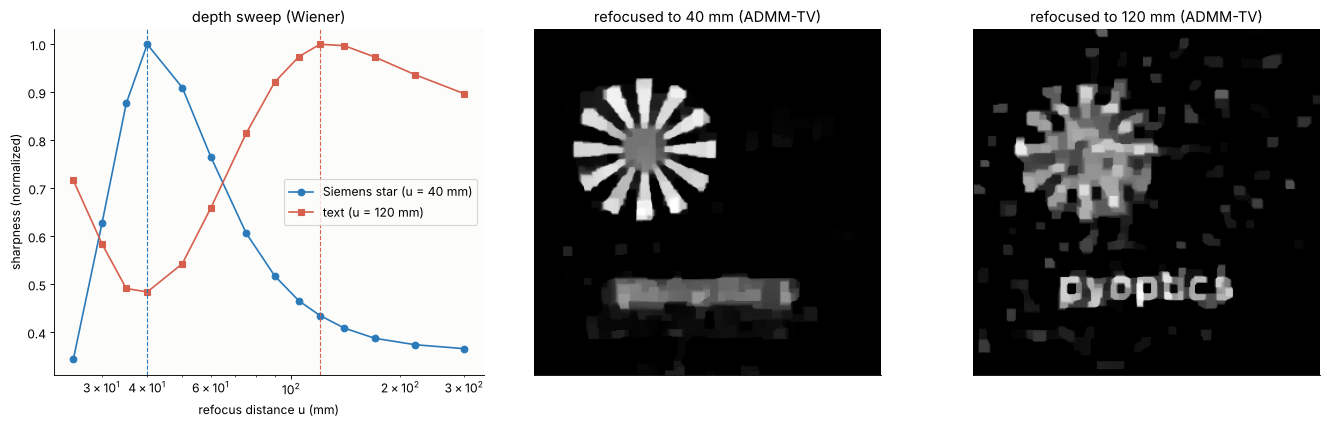

run time: 40 s


In [12]:
U2 = 120e3
psf2 = psf_at(U2)
star = siemens_star(jj, ii, -55, 45, 62, spokes=12)
text = text_image("pyoptics", n_s, 26, y=0.36)
b2_clean = ll.convolve_crop(star, psf1) + ll.convolve_crop(text, psf2)
b2_full = photons(Scaler(2000.0)(b2_clean))*b2_clean.max()/2000
b2_crop = b2_full[ll._crop_slices(b2_full.shape, SENSOR)]


def psf_for(u):
    return ll.scale_psf(psf1, ll.psf_magnification(Z_D, u)/ll.psf_magnification(Z_D, U1))


us = np.array([25, 30, 35, 40, 50, 60, 75, 90, 105, 120, 140, 170, 220, 300])*1e3
star_roi = np.hypot(jj + 55, ii - 45) < 70
text_roi = (np.abs(ii + 56) < 25) & (np.abs(jj) < 140)


def sharpness(x, region):
    gy, gx = np.gradient(x)
    return np.sum((gx**2 + gy**2)[region])/np.sum(x[region]**2)


sh = np.array([[sharpness(r, star_roi), sharpness(r, text_roi)]
               for r in (ll.wiener_deconvolve(b2_full, psf_for(u), 3e-3) for u in us)])
focus_star = ll.admm_tv_deconvolve(b2_crop, psf_for(U1), tau=1e-4, n_iter=300)
focus_text = ll.admm_tv_deconvolve(b2_crop, psf_for(U2), tau=1e-4, n_iter=300)
print("sharpest depth: star {:.0f} mm (true 40), text {:.0f} mm (true 120)".format(
    us[np.argmax(sh[:, 0])]/1e3, us[np.argmax(sh[:, 1])]/1e3))
print("correlation of the computed 120 mm PSF with the rescaled 40 mm PSF: {:.3f}".format(ncc(psf_for(U2), psf2)))

fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained")
ax[0].plot(us/1e3, sh[:, 0]/sh[:, 0].max(), "o-", color=BLUE, label="Siemens star (u = 40 mm)")
ax[0].plot(us/1e3, sh[:, 1]/sh[:, 1].max(), "s-", color=RED, label="text (u = 120 mm)")
ax[0].axvline(40, color=BLUE, ls="--", lw=1); ax[0].axvline(120, color=RED, ls="--", lw=1)
ax[0].set_xscale("log"); ax[0].set_xlabel("refocus distance u (mm)")
ax[0].set_ylabel("sharpness (normalized)"); ax[0].legend(); ax[0].set_title("depth sweep (Wiener)")
for a, (x, title) in zip(ax[1:], ((focus_star, "refocused to 40 mm"), (focus_text, "refocused to 120 mm"))):
    a.imshow(np.clip(x[view, view], 0, None), cmap="gray"); a.set_title(title + " (ADMM-TV)")
    a.set_xticks([]); a.set_yticks([])
plt.show()
print("run time: {:.0f} s".format(time.time() - t_start))

The sharpness of each object peaks at its own distance, so a single
exposure gives a focus stack, and with it the depth of the objects. The
star at 40 mm is reconstructed sharp with the 40 mm PSF, while the text
smears into a haze; with the PSF rescaled to 120 mm the text comes out and
the star breaks up into blocky artefacts. The depth resolution is
best close to the camera: the scale $1 + z/u$ changes by 7 % between
40 and 120 mm, but only by 1.5 % between 300 mm and infinity. Antipa et al.
solve for all depths at once, a 3D scene from one 2D picture, with the
same ADMM and a sum over depths in the forward model.

## Summary

- **Pinhole:** the blur is the larger of the geometric shadow ($\approx d$)
  and diffraction ($\approx 2.44\lambda v/d$). The Fresnel integral
  (`fresnel_scaled()`) reproduces the exact on-axis intensity
  $4\sin^2(\pi N/2)$ and places the best hole at about one Fresnel zone,
  $d = 1.4$ to $2.0\sqrt{\lambda v}$ depending on the criterion (Petzval
  1.56, peak per power 1.72 from $\tan x = 2x$, Rayleigh 1.9, maximum
  on-axis intensity 2.0); `ll.rayleigh_pinhole_diameter()`,
  `ll.pinhole_on_axis_intensity()`, `ll.pinhole_blur()`.
- **Coded aperture:** the MURA (`ll.mura()`, `ll.mura_decoder()`) has a
  perfect delta correlation with its decoder, so decoding is exact without
  noise. Monte Carlo photon noise confirms Fenimore's SNR
  (`ll.coded_aperture_snr()`): a gain of $\sqrt{n_\text{open}} = 43$ for a
  lone point, none once about half the field is lit. The mask elements need
  a Fresnel number $a^2/\lambda z \gtrsim 1$.
- **Diffuser camera:** a smooth random phase plate gives a caustic PSF that
  is sharpest near the focal length of its bumps
  (`ll.caustic_distance()`). The PSF shifts by $-sz/u$ and scales with
  $1 + z/u$ (`ll.psf_magnification()`, `ll.scale_psf()`, to 0.1 % in the
  scale). ADMM with total variation and the sensor crop
  (`ll.admm_tv_deconvolve()`) reconstructs a scene from a picture that
  shows nothing of it, where Wiener deconvolution fails on the crop; the
  rescaled PSF refocuses onto other depths and finds the distances of two
  objects from one exposure.

## References

- Lord Rayleigh, "On pin-hole photography", Phil. Mag. 31, 87-99 (1891).
- M. Young, "Pinhole optics", Appl. Opt. 10, 2763-2767 (1971).
- K. D. Mielenz, "On the diffraction limit for lensless imaging", J. Res. Natl. Inst. Stand. Technol. 104, 479-485 (1999).
- R. H. Dicke, "Scatter-hole cameras for X-rays and gamma rays", Astrophys. J. 153, L101-L106 (1968).
- E. E. Fenimore and T. M. Cannon, "Coded aperture imaging with uniformly redundant arrays", Appl. Opt. 17, 337-347 (1978).
- E. E. Fenimore, "Coded aperture imaging: predicted performance of uniformly redundant arrays", Appl. Opt. 17, 3562-3570 (1978).
- S. R. Gottesman and E. E. Fenimore, "New family of binary arrays for coded aperture imaging", Appl. Opt. 28, 4344-4352 (1989).
- N. Antipa, G. Kuo, R. Heckel, B. Mildenhall, E. Bostan, R. Ng and L. Waller, "DiffuserCam: lensless single-exposure 3D imaging", Optica 5, 1-9 (2018).
- V. Boominathan, J. K. Adams, M. S. Asif, B. W. Avants, J. T. Robinson, R. G. Baraniuk, A. C. Sankaranarayanan and A. Veeraraghavan, "Lensless imaging: a computational renaissance", IEEE Signal Process. Mag. 33, 23-35 (2016).
- S. Boyd, N. Parikh, E. Chu, B. Peleato and J. Eckstein, "Distributed optimization and statistical learning via the alternating direction method of multipliers", Found. Trends Mach. Learn. 3, 1-122 (2011).
- M. V. Berry and C. Upstill, "Catastrophe optics: morphologies of caustics and their diffraction patterns", Prog. Opt. 18, 257-346 (1980).
- J. W. Goodman, Introduction to Fourier Optics, 4th ed., W. H. Freeman (2017), chapter 4 (Fresnel diffraction).